# Comparing the Three-Body Model to Apollo 8

Apollo 8 (December 1968) was the first crewed mission to the Moon and was launched onto a **free-return trajectory**: if no further burns had been made after translunar injection (TLI), the spacecraft would have swung around the Moon and come straight back into Earth's atmosphere. That makes it the natural real-world check for the planar circular restricted three-body (CR3BP) model built in `FreeReturnTrajectory.ipynb`.

This notebook:

1. Records the Apollo 8 trajectory data from published NASA sources.
2. Marks where Apollo 8 **intentionally leaves** the free-return trajectory (MCC-1, LOI, TEI), so it's clear which real data the model should and shouldn't be expected to match.
3. Compares the baseline initial conditions from `FreeReturnTrajectory.ipynb` against it.
4. Seeds the model with Apollo 8's *actual* TLI state, chooses the one unknown (the phase angle $\phi$) to match Apollo 8's predicted lunar closest approach, and checks what the model predicts for everything else.
5. Grades every prediction in a **scorecard** and summarises how good the model is in the **Verdict** at the end.

**Sources**

- R. W. Orloff, *Apollo by the Numbers: A Statistical Reference*, NASA SP-2000-4029 — Apollo 8 Translunar, Lunar Orbit and Transearth phase tables, and mission narrative.
- NASA, *Apollo 8 Press Kit* (Release 68-208), 1968 — planned free-return entry time.
- NASA, *Apollo 8 Mission Report* (MSC-PA-R-69-1) — entry flight-path angle.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from freereturn.constants import *
from freereturn.dynamics import f_spacecraft
from freereturn.integrators import rk4
from freereturn.trajectory import earth_dist, moon_dist, circular_speed, inertial_speed_fpa, initial_state, trajectory_events
from freereturn.apollo8 import apollo8, apollo8_burns, apollo8_points, phase, T_MCC1, T_LOI
from freereturn.comparison import GRADE_COLOURS, grade, plot_scorecard

## Apollo 8 reference data

All values are copied from the sources above in their original units (n mi, ft/s, GET = ground elapsed time from liftoff) and converted to km, km/s and hours **after TLI**. The data lives in `freereturn/apollo8.py`, with a comment on each value saying where it came from.

A note on the lunar approach: the TLI burn was so accurate that, *with no further corrections*, Apollo 8 would have passed **458.1 n mi** above the Moon. The crew then made a midcourse correction at 011:00 GET to lower that to ~66 n mi for lunar orbit insertion (LOI). The 458.1 n mi value is the one that corresponds to a pure, uncorrected free return, which is what the model simulates.

In [2]:
for key, val in apollo8.items():
    print(f'{key:>26}: {val:10.3f}')

                   tli_alt:    346.733
                 tli_speed:     10.822
                   tli_fpa:      7.897
  perilune_alt_free_return:    848.401
                t_perilune:     66.204
                   loi_alt:    140.011
   perilune_alt_after_mcc1:    122.788
                  ei_speed:     11.040
                    ei_fpa:     -6.500
          t_ei_free_return:    133.065


### Where Apollo 8 leaves the free return

The model flies the **uncorrected** free return: TLI and then nothing. Apollo 8 made several burns after TLI, and they fall into three groups:

| Kind | Burns | Effect on the comparison |
|---|---|---|
| **Trim** | Separation 1 & 2, MCC-2, MCC-5 | A few ft/s. The path stays essentially the same, so the comparison still holds. |
| **Retarget** | MCC-1 (011:00 GET, 20.4 ft/s) | Deliberately lowered the lunar pass from 458 n mi to ~66 n mi to set up LOI. Still loops around the Moon, but it is **no longer the trajectory the model flies**, and the gap grows near the Moon. |
| **Departure** | LOI (069:08 GET), TEI (089:19 GET) | LOI braked into lunar orbit for 20 h and TEI then fired the craft home. After LOI, **Apollo 8 is not on a free return at all**, so its data cannot be compared point-for-point with the model. |

Every measured point below is tagged with which of these phases it came from.

In [3]:
for name, t, dv, kind in apollo8_burns:
    print(f'{name:<14}{t:7.1f} h after TLI  {dv:7.1f} ft/s  {kind}')

Separation 1      0.7 h after TLI      1.1 ft/s  trim
Separation 2      1.8 h after TLI      7.7 ft/s  trim
MCC-1             8.1 h after TLI     20.4 ft/s  retarget
MCC-2            58.1 h after TLI      1.4 ft/s  trim
LOI              66.2 h after TLI   2997.0 ft/s  departure
TEI              86.4 h after TLI   3519.0 ft/s  departure
MCC-5           101.1 h after TLI      4.8 ft/s  trim


## Model setup

The model is the same one used in `FreeReturnTrajectory.ipynb`, imported from the `freereturn` package: `f_spacecraft` from `freereturn/dynamics.py`, `rk4` from `freereturn/integrators.py`, and the constants from `freereturn/constants.py`.

The model state is in the rotating frame, but Apollo reports *space-fixed* (inertial, Earth-centred) speed and flight-path angle. With $\omega = 1$ in nondimensional units, the Earth-centred inertial velocity is

$$
\vec v_{in} = \vec v_{rot} + \vec\omega \times \vec r_E = \begin{bmatrix} v_x - y \\ v_y + (x + \mu) \end{bmatrix}
$$

and the flight-path angle is the angle of $\vec v_{in}$ above the local horizontal: $\gamma = \sin^{-1}\left(\frac{\vec r_E \cdot \vec v_{in}}{|\vec r_E| |\vec v_{in}|}\right)$.

These conversions, plus the initial-state builder and the perilune and entry-interface event detection, are in `freereturn/trajectory.py`.

## 1. The project's nominal free return

The nominal from `FreeReturnTrajectory.ipynb` is a tangential burn ($\gamma = 0$) from a 185 km circular orbit at phase angle $\phi = 4.12$ rad, with the TLI magnitude retargeted by `scripts/retarget_nominal.py` so that the return enters at $\gamma_{EI} = -6.52^\circ$. It is read from `results/nominal.json`.

In [4]:
import json
from freereturn.trajectory import tli_state

nominal = json.load(open('results/nominal.json'))
delta_v = nominal['delta_v_kms'] # km/s
phi = nominal['phi_rad'] # rad

u_base_start = tli_state(delta_v, phi)

t_f_ND = 2
dt_ND = t_f_ND/2**15

u_base, times_base = rk4(f_spacecraft, u_base_start, t_f_ND, dt_ND)
ev_base = trajectory_events(u_base, times_base)

base_speed, base_fpa = inertial_speed_fpa(u_base_start)

print(f'TLI altitude      model {R_0 - R_EARTH:9.1f} km    Apollo 8 {apollo8["tli_alt"]:9.1f} km')
print(f'TLI speed         model {base_speed:9.3f} km/s  Apollo 8 {apollo8["tli_speed"]:9.3f} km/s')
print(f'TLI FPA           model {base_fpa:9.3f} deg   Apollo 8 {apollo8["tli_fpa"]:9.3f} deg')
print(f'Perilune altitude model {ev_base["perilune_alt"]:9.1f} km    Apollo 8 {apollo8["perilune_alt_free_return"]:9.1f} km')
print(f'Time to perilune  model {ev_base["t_perilune"]:9.1f} h     Apollo 8 {apollo8["t_perilune"]:9.1f} h')
print(f'Reaches entry interface: {ev_base["entered"]}' + (f', gamma_EI = {ev_base["ei_fpa"]:.2f} deg' if ev_base['entered'] else ''))
if not ev_base['entered']:
    print(f'Return perigee altitude {ev_base["return_perigee_alt"]:.1f} km at {ev_base["t_ei"]:.1f} h (entry interface is {R_EI - R_EARTH:.1f} km)')

TLI altitude      model     185.0 km    Apollo 8     346.7 km
TLI speed         model    10.937 km/s  Apollo 8    10.822 km/s
TLI FPA           model     0.000 deg   Apollo 8     7.897 deg
Perilune altitude model    6947.4 km    Apollo 8     848.4 km
Time to perilune  model      90.5 h     Apollo 8      66.2 h
Reaches entry interface: True, gamma_EI = -6.52 deg


The nominal burns from a lower orbit with a slightly higher speed and no flight-path angle, so it arrives at the Moon later and passes much further from it than Apollo 8 would have. Unlike Apollo 8 seeded below, it is targeted at the entry corridor, so it re-enters at $-6.52^\circ$.

## 2. Model seeded with Apollo 8's actual TLI state

Apollo 8's real TLI altitude, speed and flight-path angle are used directly. The only quantity that doesn't carry over is the phase angle $\phi$, since the real trajectory was three-dimensional (the parking orbit was inclined 32.5°) and the Moon's position isn't modelled the same way. $\phi$ is chosen by bisection so the model's closest lunar approach matches Apollo 8's uncorrected free-return value of 458.1 n mi; everything else is a prediction.

On the free-return branch (the spacecraft passes behind the Moon and returns in a figure-8), perilune altitude increases with $\phi$ between roughly 4.246 and 4.252 rad (found by scanning $\phi$; at smaller $\phi$ the trajectory hits the Moon, at larger $\phi$ it no longer returns).

In [5]:
r_tli = R_EARTH + apollo8['tli_alt']

t_f_ND = 1.6
dt_ND = t_f_ND/2**15

def perilune_alt(phi):
    u, times = rk4(f_spacecraft, initial_state(r_tli, apollo8['tli_speed'], apollo8['tli_fpa'], phi), t_f_ND, dt_ND)
    return moon_dist(u).min() - R_MOON

phi_lo, phi_hi = 4.246, 4.252

for i in range(25):
    phi_mid = 0.5*(phi_lo + phi_hi)
    if perilune_alt(phi_mid) < apollo8['perilune_alt_free_return']:
        phi_lo = phi_mid
    else:
        phi_hi = phi_mid

phi_a8 = 0.5*(phi_lo + phi_hi)

u_a8, times_a8 = rk4(f_spacecraft, initial_state(r_tli, apollo8['tli_speed'], apollo8['tli_fpa'], phi_a8), t_f_ND, dt_ND)
ev_a8 = trajectory_events(u_a8, times_a8)

print(f'phi = {phi_a8:.6f} rad')
print(f'Perilune altitude {ev_a8["perilune_alt"]:.1f} km, reaches entry interface: {ev_a8["entered"]}')

phi = 4.248704 rad
Perilune altitude 848.4 km, reaches entry interface: True


## Results: how good is the model?

Each comparison is one of three kinds, and only the last one says anything about the model's accuracy:

- **Input**: copied from Apollo 8 into the model, so it matches by construction.
- **Targeted**: $\phi$ was chosen to make this match.
- **Predicted**: nothing was tuned to it. This is the real test.

Predictions are graded on percent error: **Close match** (< 5%), **Reasonable** (5–15%), **Off** (> 15%). The **Apollo source** column shows which phase of the flight the real value comes from. Apollo 8 data from after LOI is only compared where the quantity barely depends on the route home (entry speed) or where a pre-flight free-return plan exists (entry time).

In [6]:
t_a8_h = times_a8 * T / 3600

def model_dist_at(t, body):
    d = earth_dist(u_a8) if body == 'earth' else moon_dist(u_a8)
    return np.interp(t, t_a8_h, d)

# (name, model, Apollo 8, unit, role, Apollo source)
comparisons = [
    ('TLI altitude', r_tli - R_EARTH, apollo8['tli_alt'], 'km', 'input', 'free return'),
    ('TLI speed', inertial_speed_fpa(u_a8[0])[0], apollo8['tli_speed'], 'km/s', 'input', 'free return'),
    ('TLI flight-path angle', inertial_speed_fpa(u_a8[0])[1], apollo8['tli_fpa'], 'deg', 'input', 'free return'),
    ('Perilune altitude', ev_a8['perilune_alt'], apollo8['perilune_alt_free_return'], 'km', 'targeted', 'free return'),
]

# Distances along the coast, only where Apollo 8 was still on (or near) the free return
for name, t, body, dist in apollo8_points:
    if name == 'TLI' or phase(t) == 'after LOI':
        continue
    comparisons.append((f'{body.capitalize()} distance, {name} ({t:.0f} h)', model_dist_at(t, body), dist, 'km', 'predicted', phase(t)))

comparisons += [
    ('Time TLI -> Moon', ev_a8['t_perilune'], apollo8['t_perilune'], 'h', 'predicted', 'after MCC-1'),
    ('Time TLI -> entry interface', ev_a8['t_ei'], apollo8['t_ei_free_return'], 'h', 'predicted', 'planned free return'),
    ('Entry speed', ev_a8['ei_speed'], apollo8['ei_speed'], 'km/s', 'predicted', 'after LOI'),
    ('Entry flight-path angle', ev_a8['ei_fpa'], apollo8['ei_fpa'], 'deg', 'predicted', 'after LOI'),
]

print(f'{"":<40}{"Model":>11}{"Apollo 8":>11}{"Error":>9}  {"Unit":<5} {"Role":<10}{"Grade":<13}Apollo source')
print('-'*125)
for name, model, real, unit, role, source in comparisons:
    pct = 100*(model - real)/abs(real)
    print(f'{name:<40}{model:>11.3f}{real:>11.3f}{pct:>8.1f}%  {unit:<5} {role:<10}{grade(pct) if role == "predicted" else "-":<13}{source}')

                                              Model   Apollo 8    Error  Unit  Role      Grade        Apollo source
-----------------------------------------------------------------------------------------------------------------------------
TLI altitude                                346.733    346.733    -0.0%  km    input     -            free return
TLI speed                                    10.822     10.822    -0.0%  km/s  input     -            free return
TLI flight-path angle                         7.897      7.897     0.0%  deg   input     -            free return
Perilune altitude                           848.401    848.401     0.0%  km    targeted  -            free return
Earth distance, CSM separation (0 h)      13414.677  13411.644     0.0%  km    predicted Close match  free return
Earth distance, MCC-1 ignition (8 h)     104121.835 104105.242     0.0%  km    predicted Close match  free return
Earth distance, Gravity crossover (53 h) 334242.417 326415.000     2.4%  k

### Scorecard

The chart below shows only the **predicted** quantities. Bar length is the size of the percent error, and colour plus the text label give the grade. Hatched bars mark comparisons where the Apollo value does *not* come from the uncorrected free return the model flies (after MCC-1, after LOI, or a pre-flight plan). Treat those as a looser check.

9 predicted quantities: 5 close match, 2 reasonable, 2 off


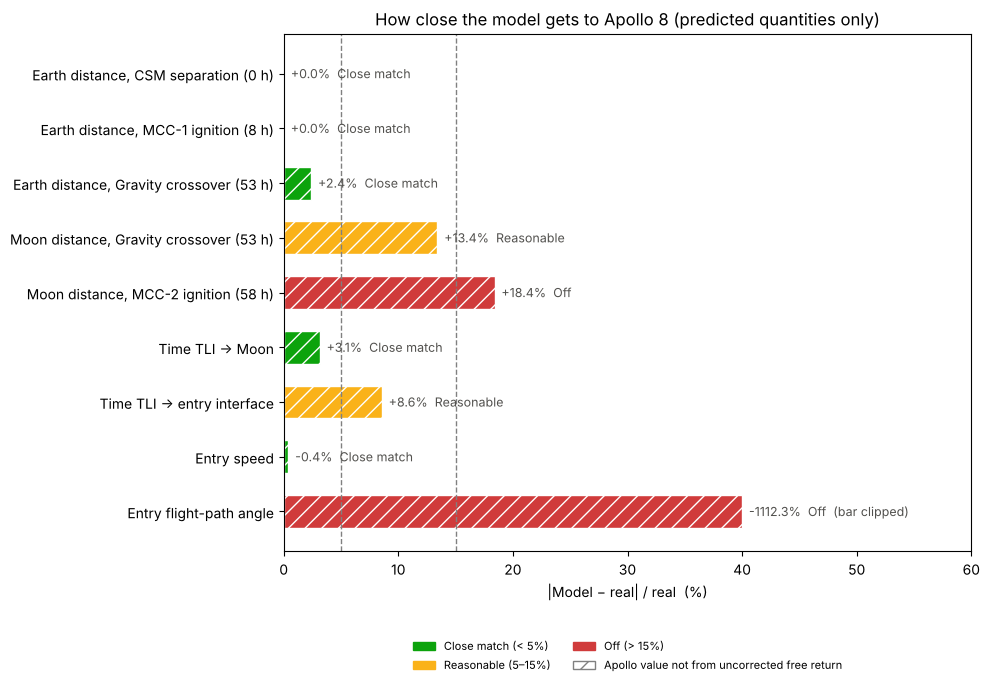

In [7]:
predicted = [c for c in comparisons if c[4] == 'predicted']
names = [c[0] for c in predicted]
pct_errors = np.array([100*(c[1] - c[2])/abs(c[2]) for c in predicted])

fig1 = plt.figure(figsize=(10, 0.5*len(predicted) + 2.5))
ax11 = fig1.add_subplot(111)
plot_scorecard(ax11, names, pct_errors, [c[5] != 'free return' for c in predicted],
               'How close the model gets to Apollo 8 (predicted quantities only)',
               'Apollo value not from uncorrected free return')
fig1.tight_layout()

counts = {g: sum(grade(p) == g for p in pct_errors) for g in GRADE_COLOURS}
print(f'{len(predicted)} predicted quantities: ' + ', '.join(f'{n} {g.lower()}' for g, n in counts.items()))

## Trajectory vs time, with Apollo 8's burns

Vertical lines mark every burn Apollo 8 made. Thin dotted lines are trims. Labelled lines are the burns that **intentionally take Apollo 8 off the free return the model flies**: MCC-1 retargets the lunar pass, and LOI/TEI leave the free return entirely. The shaded region is after LOI, when Apollo 8 was in lunar orbit and then on a different route home, so the model is not expected to follow it there.

Marker shape shows which phase each measurement came from.

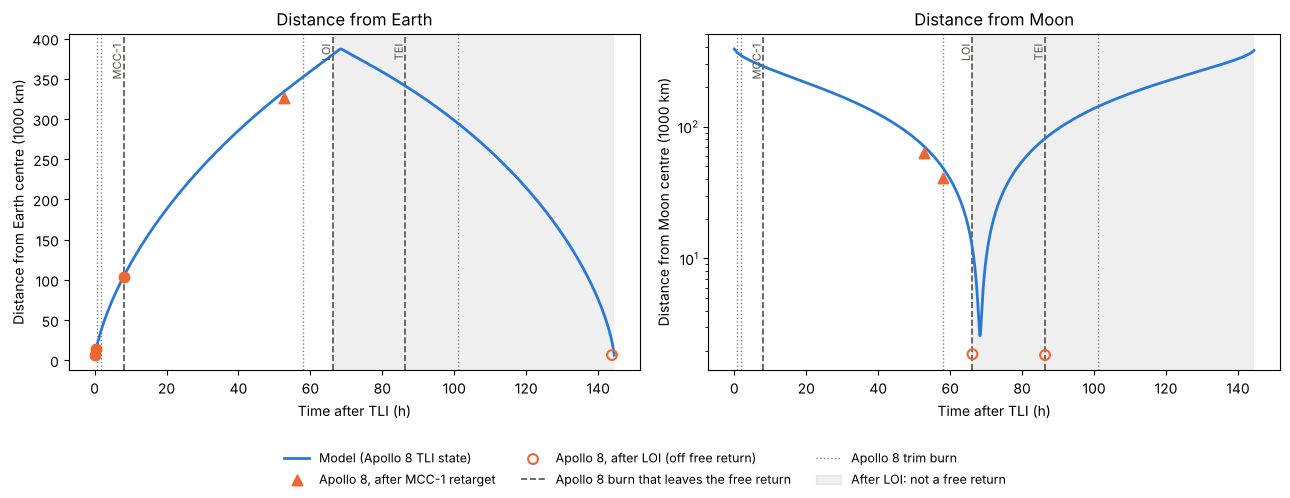

In [8]:
MODEL_COLOUR = '#2a78d6'
APOLLO_COLOUR = '#eb6834'
PHASE_MARKERS = {
    'free return': dict(marker='o', facecolors=APOLLO_COLOUR, label='Apollo 8, on free return'),
    'after MCC-1': dict(marker='^', facecolors=APOLLO_COLOUR, label='Apollo 8, after MCC-1 retarget'),
    'after LOI': dict(marker='o', facecolors='none', label='Apollo 8, after LOI (off free return)'),
}

# stop the model curves at entry interface
n_ei = ev_a8['ei_idx'] + 2

def mark_burns(ax):
    ax.axvspan(T_LOI, t_a8_h[n_ei], color='GREY', alpha=0.12, lw=0)
    for name, t, dv, kind in apollo8_burns:
        if kind == 'trim':
            ax.axvline(t, color='GREY', ls=':', lw=1)
        else:
            ax.axvline(t, color='#52514e', ls='--', lw=1.2)
            ax.text(t, 0.98, f' {name} ', transform=ax.get_xaxis_transform(), rotation=90,
                    va='top', ha='right', fontsize=8, color='#52514e')

fig2 = plt.figure(figsize=(13, 5))
ax21 = fig2.add_subplot(121)
ax22 = fig2.add_subplot(122)

for ax, body, dist in ((ax21, 'earth', earth_dist), (ax22, 'moon', moon_dist)):
    mark_burns(ax)
    ax.plot(t_a8_h[:n_ei], dist(u_a8[:n_ei])/1000, color=MODEL_COLOUR, lw=2, label='Model (Apollo 8 TLI state)')

    for ph, style in PHASE_MARKERS.items():
        pts = np.array([(t, d) for name, t, b, d in apollo8_points if b == body and phase(t) == ph])
        if len(pts):
            ax.scatter(pts[:, 0], pts[:, 1]/1000, s=50, edgecolors=APOLLO_COLOUR, linewidths=1.5, zorder=3, **style)

    ax.set_xlabel('Time after TLI (h)')

ax21.set_title('Distance from Earth')
ax21.set_ylabel('Distance from Earth centre (1000 km)')

ax22.set_title('Distance from Moon')
ax22.set_ylabel('Distance from Moon centre (1000 km)')
ax22.set_yscale('log')

handles, labels = ax22.get_legend_handles_labels()
handles += [plt.Line2D([], [], color='#52514e', ls='--', lw=1.2), plt.Line2D([], [], color='GREY', ls=':', lw=1),
            plt.Rectangle((0, 0), 1, 1, color='GREY', alpha=0.12)]
labels += ['Apollo 8 burn that leaves the free return', 'Apollo 8 trim burn', 'After LOI: not a free return']
fig2.legend(handles, labels, loc='lower center', ncol=3, fontsize=9, frameon=False)

fig2.tight_layout(rect=(0, 0.12, 1, 1))

Before MCC-1 (the circles), the model and Apollo 8 fly the same trajectory and the points sit on the curve. After MCC-1 (triangles), Apollo 8 aims for a lower, slightly later lunar pass, so the gap between them grows as they approach the Moon. After LOI (hollow circles), Apollo 8 is in lunar orbit and then on its transearth leg while the model swings straight past the Moon. Those points are there to show *where* the real flight departs from the free return, not to grade the model.

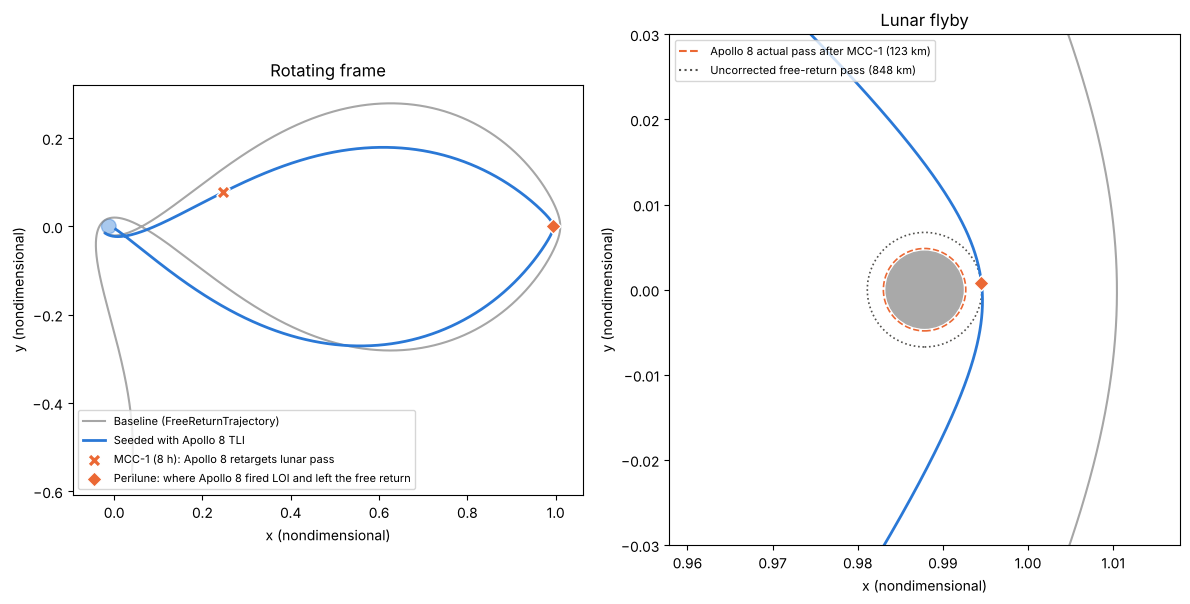

In [9]:
fig3 = plt.figure(figsize=(12, 6))
ax31 = fig3.add_subplot(121)
ax32 = fig3.add_subplot(122)

k = ev_a8['perilune_idx']
k_mcc1 = np.argmin(np.abs(t_a8_h - T_MCC1))

for ax in (ax31, ax32):
    ax.plot(u_base[:, 0], u_base[:, 1], label='Baseline (FreeReturnTrajectory)', color='GREY', alpha=0.7)
    ax.plot(u_a8[:n_ei, 0], u_a8[:n_ei, 1], color=MODEL_COLOUR, lw=2, label='Seeded with Apollo 8 TLI')
    ax.add_patch(plt.Circle((-MU, 0), R_EARTH/L, color=MODEL_COLOUR, alpha=0.4))
    ax.add_patch(plt.Circle((1 - MU, 0), R_MOON/L, color='DARKGREY'))
    ax.scatter(u_a8[k_mcc1, 0], u_a8[k_mcc1, 1], marker='X', s=90, color=APOLLO_COLOUR, edgecolors='WHITE', zorder=4,
               label=f'MCC-1 ({T_MCC1:.0f} h): Apollo 8 retargets lunar pass')
    ax.scatter(u_a8[k, 0], u_a8[k, 1], marker='D', s=60, color=APOLLO_COLOUR, edgecolors='WHITE', zorder=4,
               label='Perilune: where Apollo 8 fired LOI and left the free return')
    ax.set_aspect('equal')
    ax.set_xlabel('x (nondimensional)')
    ax.set_ylabel('y (nondimensional)')

ax31.set_title('Rotating frame')
ax31.legend(loc='lower left', fontsize=8)

# Apollo 8's actual lunar pass after the MCC-1 retarget vs the free-return pass the model flies
ax32.add_patch(plt.Circle((1 - MU, 0), (R_MOON + apollo8['perilune_alt_after_mcc1'])/L, fill=False, ls='--', color=APOLLO_COLOUR, lw=1.2))
ax32.add_patch(plt.Circle((1 - MU, 0), (R_MOON + apollo8['perilune_alt_free_return'])/L, fill=False, ls=':', color='#52514e', lw=1.2))
ax32.legend(handles=[
    plt.Line2D([], [], color=APOLLO_COLOUR, ls='--', label=f'Apollo 8 actual pass after MCC-1 ({apollo8["perilune_alt_after_mcc1"]:.0f} km)'),
    plt.Line2D([], [], color='#52514e', ls=':', label=f'Uncorrected free-return pass ({apollo8["perilune_alt_free_return"]:.0f} km)'),
], loc='upper left', fontsize=8)
ax32.set_title('Lunar flyby')
ax32.set_xlim(1 - MU - 0.03, 1 - MU + 0.03)
ax32.set_ylim(-0.03, 0.03)

fig3.tight_layout()

## Verdict

**The planar CR3BP model reproduces the shape and energy of Apollo 8's free return well, and its timing reasonably. It does not reproduce the entry geometry.** Only the perilune altitude was tuned; everything below is a prediction.

- **Close match (< 5%).** The outbound coast for the first ~8 hours, while Apollo 8 was still on the uncorrected free return (0.0% error in distance from Earth at both points), distance from Earth at the gravity crossover (2.4%), time to reach the Moon (~2 h late, 3.1%), and entry speed (0.4%): the model gets the energy of a fall from lunar distance almost exactly right.
- **Reasonable (5–15%).** Distance from the Moon at the gravity crossover (13%) and total time to get home (~11 h later than the pre-flight plan, 8.6%).
- **Off (> 15%).** Distance from the Moon at MCC-2, two hours before the flyby (18%), and entry flight-path angle.
  - **Near the Moon**, the craft is moving fast relative to the Moon, so a ~2 h arrival offset becomes tens of thousands of km of distance error. These points also come from after MCC-1, which retargeted the real flight to a lower pass.
  - **The entry angle** of −79° vs −6.5° is the model's real miss, and it is the point of the project. Only perilune altitude was targeted here, and the return is extremely sensitive to the outbound state: `scripts/select_dt.py` measures about 0.14° of entry angle per mm/s of TLI error at the nominal. Correcting the model constants, mainly making the time unit consistent with $L$ and the masses (a 0.13% change), moved this untargeted entry angle from −15° to −79°. An untargeted planar trajectory can land anywhere relative to the corridor, which is why the entry angle has to be targeted directly (Q1) and corrected in flight (Q2).

## Why the model and the flight differ

Where they disagree, the main causes are things the planar CR3BP leaves out, plus the burns Apollo 8 made on purpose:

- **Intentional divergences.** MCC-1 lowered the lunar pass from 458 to 66 n mi, LOI put Apollo 8 into lunar orbit for 20 h, and TEI sent it home on a different trajectory. Real data from after each of these burns measures a *different trajectory* from the one the model flies.
- **Three dimensions.** Apollo 8's parking orbit was inclined 32.5° and the Moon's orbit is inclined about 5° to the ecliptic. The real trajectory was not in the Earth–Moon plane, so a planar model cannot match both the geometry and the timing exactly.
- **Circular lunar orbit.** The model holds the Moon at $L = 384{,}400$ km. The real Earth–Moon distance changes by about ±5% over a month, which directly changes the coast time.
- **Other forces.** The Sun's gravity, Earth's oblateness ($J_2$) and the real ephemeris are all left out. Over a 6-day trip these move the trajectory by tens to hundreds of km.
- **Targeting.** Real free-return trajectories are tuned so the return perigee lands inside a narrow entry corridor (around −6.5°). Here only perilune altitude was targeted, so the entry angle is a consequence and not a constraint.